# How big are the split PDFs if we cut at Tier A covers only?

Follow-up to `landscape_analysis.ipynb` and `cover_candidates.ipynb`. Each reel is one PDF of roughly 1,000 pages, which is too big to process. Before doing a careful job of finding every file boundary, we only need to get each piece down to a workable size (target: **at most ~100 pages**).

So: cut each reel at every Tier A candidate cover (the high-precision rule, ~96% in the hand-labeled sample), and look at the resulting piece sizes. Pieces that are still too large are the ones that need further attention.

Input: `nara_reel_tif_image_dimensions.csv`. Sizes here are in **pages**; the file has no byte sizes.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MAX_PAGES = 100          # target upper bound for a split PDF
SKIP_FIRST = 2           # reel positions 1-2 are front matter, never a cut point

## 1. Load, and flag cut points

Tier A rule is copied from `cover_candidates.ipynb`. Per its follow-up note, positions 1-2 of a reel are excluded (the two Tier A false positives in the sample were both page 2).

In [3]:
df = pd.read_csv("nara_reel_tif_image_dimensions.csv")
parts = df.pageImageURL.str.extract(r"M804-(\d+)/M804-\d+-(\d+)")
df["reel"] = parts[0].astype(int)
df["page"] = parts[1].astype(int)
df = df.sort_values(["reel", "page"]).reset_index(drop=True)
df["aspect"] = df.width / df.height
df["pos"] = df.groupby("reel").cumcount() + 1     # 1-based position (page numbers can have gaps)

tier_a = ((df.width > df.height)
          & df.width.between(6000, 6700) & df.height.between(4300, 4700)
          & df.aspect.between(1.38, 1.47))
df["cut"] = tier_a & (df.pos > SKIP_FIRST)         # a new piece STARTS at this page
print(f"{len(df):,} pages, {df.reel.nunique()} reels | Tier A: {tier_a.sum():,} | usable cut points: {df.cut.sum():,}")

75,804 pages, 74 reels | Tier A: 2,362 | usable cut points: 2,360


## 2. Build the pieces

Within a reel, a new piece starts at each cut page, so the cover stays with the file it opens. Everything before the first cut (front matter plus the first file's stub, if any) is piece 0 of that reel.

In [4]:
df["piece"] = df.groupby("reel").cut.cumsum()      # 0 = before the first cut
pieces = (df.groupby(["reel", "piece"])
            .agg(pages=("page", "size"), first_pos=("pos", "min"), last_pos=("pos", "max"))
            .reset_index())
print(f"{len(pieces):,} pieces from {df.reel.nunique()} reels")
pieces.pages.describe().round(1).to_frame("pages per piece").T

2,434 pieces from 74 reels


,count,mean,std,min,25%,50%,75%,max
pages per piece,2434.0,31.1,28.1,1.0,14.0,24.0,42.0,258.0


## 3. Size distribution

In [5]:
rows = []
for t in (50, 100, 150, 200):
    over = pieces[pieces.pages > t]
    rows.append({"threshold": f"> {t} pages", "pieces": len(over),
                 "% of pieces": round(len(over) / len(pieces) * 100, 1),
                 "pages inside them": over.pages.sum(),
                 "% of all pages": round(over.pages.sum() / len(df) * 100, 1)})
pd.DataFrame(rows)

,threshold,pieces,% of pieces,pages inside them,% of all pages
0,> 50 pages,433,17.8,33879,44.7
1,> 100 pages,61,2.5,8242,10.9
2,> 150 pages,13,0.5,2586,3.4
3,> 200 pages,6,0.2,1331,1.8


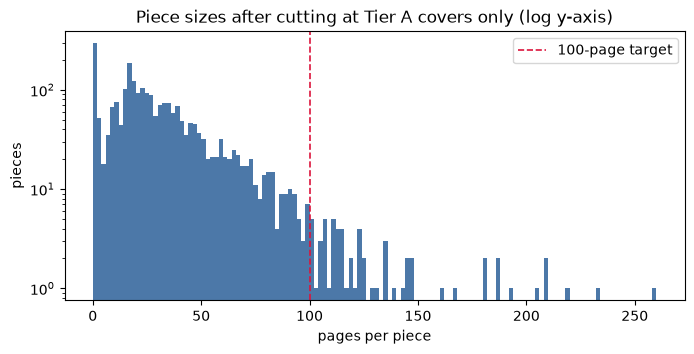

In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(pieces.pages, bins=130, range=(0, 260), color="#4c78a8")
ax.axvline(MAX_PAGES, color="crimson", ls="--", lw=1.2, label=f"{MAX_PAGES}-page target")
ax.set_xlabel("pages per piece"); ax.set_ylabel("pieces"); ax.set_yscale("log"); ax.legend()
ax.set_title("Piece sizes after cutting at Tier A covers only (log y-axis)")
plt.show()

## 4. The pieces that are still too big

In [7]:
big = pieces[pieces.pages > MAX_PAGES].sort_values("pages", ascending=False)
print(f"{len(big)} pieces over {MAX_PAGES} pages, in {big.reel.nunique()} of {df.reel.nunique()} reels")
big.head(15)

61 pieces over 100 pages, in 39 of 74 reels


,reel,piece,pages,first_pos,last_pos
2078,1880,17,258,517,774
1725,1844,1,233,17,249
1346,1816,17,219,168,386
328,1724,33,208,1110,1317
168,1602,14,208,363,570
2222,1913,16,205,192,396
2394,1950,3,193,82,274
701,1764,12,187,531,717
2122,1883,4,187,73,259
1804,1846,23,181,826,1006


In [8]:
# Is oversize concentrated in a few reels?
per_reel = pieces.groupby("reel").agg(pieces=("pages", "size"), max_piece=("pages", "max"),
                                      over=("pages", lambda s: (s > MAX_PAGES).sum()))
per_reel["total_pages"] = df.groupby("reel").size()
print("Reels with the most oversize pieces:")
display(per_reel.sort_values("over", ascending=False).head(8))
print("Reels with no oversize pieces:", (per_reel.over == 0).sum(), "of", len(per_reel))

Reels with the most oversize pieces:


,pieces,max_piece,over,total_pages
reel,,,,
1845,26,146,4,1127
1816,44,219,3,1086
1847,41,119,3,1243
1840,30,106,3,1184
1950,19,193,3,981
1764,24,187,2,1193
1724,34,208,2,1317
1719,39,135,2,1167


Reels with no oversize pieces: 35 of 74


### Piece 0 (before the first cut)

This is where front matter lands. A reel whose first cover is far from the start would show up here as a large piece 0.

In [9]:
p0 = pieces[pieces.piece == 0]
print(p0.pages.describe().round(1).to_string())
p0[p0.pages > 25].sort_values("pages", ascending=False)

count    74.0
mean     19.8
std      11.9
min      16.0
25%      17.0
50%      17.0
75%      17.0
max      95.0


,reel,piece,pages,first_pos,last_pos
871,1782,0,95,1,95
1781,1846,0,70,1,70
1640,1840,0,48,1,48
768,1777,0,42,1,42
329,1728,0,35,1,35
2391,1950,0,27,1,27


## 5. Splitting the oversize pieces with Tier B candidates

Tier B (other landscape pages) is mostly noise overall (~15% covers in the labeled sample), but the covers hiding in it were "just outside" the Tier A box. The box below is fitted to the 6 labeled Tier B covers, so it is a **near-miss box**, not a validated rule:
width 6250-6800, height 4550-4850, aspect 1.36-1.45. We first check how well it separates the 40 labeled Tier B pages.

In [10]:
def near_box(d):
    return (d.width.between(6250, 6800) & d.height.between(4550, 4850) & d.aspect.between(1.36, 1.45))

lab = pd.read_csv("labeling/labels.csv").merge(pd.read_csv("labeling/sample_key.csv"), on=["sample_id", "reel", "page"])
lb = lab[lab.tier == "B"].assign(in_box=lambda d: near_box(d))
print("Labeled tier B pages vs near-miss box:")
display(pd.crosstab(lb.label, lb.in_box))
print("Caveat: the box was fitted to these same 6 covers, so this is an in-sample fit. Tier B has ~200 such pages overall, "
      "close to the ~205 covers estimated in Tier B, which is encouraging but not proof.")

Labeled tier B pages vs near-miss box:


in_box,False,True
label,,
cover,0,6
front_matter,8,0
not_cover,26,0


Caveat: the box was fitted to these same 6 covers, so this is an in-sample fit. Tier B has ~200 such pages overall, close to the ~205 covers estimated in Tier B, which is encouraging but not proof.


In [11]:
land = df.width > df.height
df["near"] = land & ~tier_a & (df.pos > SKIP_FIRST) & near_box(df)       # candidate cut, "Tier B+"
df["any_b"] = land & ~tier_a & (df.pos > SKIP_FIRST)                      # any other landscape page

print(f"Tier B+ (near-miss box): {df.near.sum()} pages;  other landscape (still tier B): {(df.any_b & ~df.near).sum()} pages")
over = pieces[pieces.pages > MAX_PAGES]
cnt = lambda col: df.merge(over[["reel", "piece"]]).groupby(["reel", "piece"])[col].sum()
print(f"Of the {len(over)} oversize pieces: {(cnt('near') > 0).sum()} contain a Tier B+ page, "
      f"{(cnt('any_b') > 0).sum()} contain any landscape page")

Tier B+ (near-miss box): 200 pages;  other landscape (still tier B): 1075 pages
Of the 61 oversize pieces: 31 contain a Tier B+ page, 49 contain any landscape page


### Choosing the cuts

For each oversize piece, repeatedly take the candidate that leaves the most balanced two halves (smallest larger half), and recurse on any half still over the cap. That uses as few candidates as possible and keeps pieces roughly even. A candidate starts a new piece, same as a cover.

In [12]:
def pick_cuts(cands, start, end, cap=MAX_PAGES):
    # cands: sorted positions; piece covers positions start..end inclusive; cut at c => new piece starts at c
    if end - start + 1 <= cap:
        return []
    inside = [c for c in cands if start < c <= end]
    if not inside:
        return []
    c = min(inside, key=lambda c: max(c - start, end - c + 1))
    return pick_cuts(cands, start, c - 1, cap) + [c] + pick_cuts(cands, c, end, cap)

def apply_cuts(flag):
    cands_by_reel = df[df[flag]].groupby("reel").pos.apply(sorted).to_dict()
    out = []
    for r in pieces.itertuples():
        cuts = pick_cuts(cands_by_reel.get(r.reel, []), r.first_pos, r.last_pos) if r.pages > MAX_PAGES else []
        edges = [r.first_pos] + cuts + [r.last_pos + 1]
        for a, b in zip(edges, edges[1:]):
            out.append({"reel": r.reel, "piece": r.piece, "start": a, "pages": b - a, "added_cut": a in cuts})
    return pd.DataFrame(out)

s_near = apply_cuts("near")
df["near_or_b"] = df.near | df.any_b
s_all = apply_cuts("near_or_b")

rows = []
for name, s in [("Tier A only", pieces.rename(columns={"first_pos": "start"})), ("+ Tier B+ (near-miss box)", s_near), ("+ any landscape page", s_all)]:
    rows.append({"cuts used": name, "PDFs": len(s), "over cap": (s.pages > MAX_PAGES).sum(),
                 "largest": s.pages.max(), "pages still in oversize PDFs": s.pages[s.pages > MAX_PAGES].sum(),
                 "Tier B cuts added": int(s.added_cut.sum()) if "added_cut" in s else 0})
pd.DataFrame(rows)

,cuts used,PDFs,over cap,largest,pages still in oversize PDFs,Tier B cuts added
0,Tier A only,2434,61,258,8242,0
1,+ Tier B+ (near-miss box),2473,39,199,4838,39
2,+ any landscape page,2494,20,199,2431,60


In [13]:
rem = s_near[s_near.pages > MAX_PAGES].sort_values("pages", ascending=False)
print(f"After Tier B+ cuts, {len(rem)} PDFs remain over {MAX_PAGES} pages (largest {rem.pages.max() if len(rem) else 0}):")
rem.head(12)

After Tier B+ cuts, 39 PDFs remain over 100 pages (largest 199):


,reel,piece,start,pages,added_cut
169,1602,14,363,199,False
779,1777,1,43,180,False
629,1755,10,265,167,False
1359,1816,17,190,166,True
679,1763,10,263,160,False
1829,1846,23,859,148,True
2137,1881,20,606,147,False
1105,1799,17,422,145,False
710,1764,12,540,138,True
638,1755,19,807,134,False


### The chosen Tier B+ cuts

These are the pages that would be cut, with their dimensions. They are **unlabeled**, so spot-check them (open the TIFF links) before relying on them. The sheet lists every cut in reel order, with the piece sizes it produces.

In [14]:
chosen = df.merge(s_near[s_near.added_cut][["reel", "start"]].rename(columns={"start": "pos"}))
chosen = chosen.merge(pieces[["reel", "piece", "pages"]].rename(columns={"pages": "orig_piece_pages"}), on=["reel", "piece"])
print(len(chosen), "Tier B+ cuts chosen across", chosen.groupby(["reel", "piece"]).ngroups, "oversize pieces")
chosen[["reel", "page", "pos", "width", "height", "aspect", "orig_piece_pages", "pageImageURL"]].round(3).head(15)

39 Tier B+ cuts chosen across 31 oversize pieces


,reel,page,pos,width,height,aspect,orig_piece_pages,pageImageURL
0,1571,724,724,6393,4633,1.380,142,https://catalog.archives.gov/medialz/dc-metro/...
1,1602,562,562,6633,4761,1.393,208,https://catalog.archives.gov/medialz/dc-metro/...
2,1602,815,815,6729,4825,1.395,129,https://catalog.archives.gov/medialz/dc-metro/...
3,1719,312,312,6681,4745,1.408,135,https://catalog.archives.gov/medialz/dc-metro/...
4,1719,1005,1005,6649,4713,1.411,108,https://catalog.archives.gov/medialz/dc-metro/...
5,1724,1209,1209,6584,4744,1.388,208,https://catalog.archives.gov/medialz/dc-metro/...
6,1724,1238,1238,6616,4744,1.395,208,https://catalog.archives.gov/medialz/dc-metro/...
7,1752,243,243,6377,4633,1.376,130,https://catalog.archives.gov/medialz/dc-metro/...
8,1764,540,540,6409,4681,1.369,187,https://catalog.archives.gov/medialz/dc-metro/...
9,1764,678,678,6505,4729,1.376,187,https://catalog.archives.gov/medialz/dc-metro/...


In [15]:
chosen[["reel", "page", "pos", "width", "height", "aspect", "orig_piece_pages", "pageImageURL"]].to_csv("tier_b_plus_cuts.csv", index=False)

### Collage of the Tier B+ cuts

Thumbnails of every chosen cut page (the page that would *start* a new piece), so you can eyeball whether they look like file jackets. Each one is downloaded once (~30 MB TIFF) and cached in `labeling/cut_thumbs/`.

In [16]:
import io, requests
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
Image.MAX_IMAGE_PIXELS = None

THUMB_DIR = Path("labeling/cut_thumbs"); THUMB_DIR.mkdir(parents=True, exist_ok=True)

def fetch_cut_thumb(row):
    path = THUMB_DIR / f"{row.reel}_{row.page:04d}.jpg"
    if path.exists():
        return None
    for _ in range(4):
        try:
            r = requests.get(row.pageImageURL, timeout=120); r.raise_for_status()
            im = Image.open(io.BytesIO(r.content)); im.load()
            im = im.convert("L") if im.mode in ("1", "L", "I;16") else im.convert("RGB")
            im.thumbnail((1000, 1000), Image.LANCZOS); im.save(path, quality=80)
            return None
        except Exception as e:
            err = repr(e)
    return (row.reel, row.page, err)

with ThreadPoolExecutor(6) as ex:
    failed = [x for x in ex.map(fetch_cut_thumb, chosen.itertuples()) if x]
print(f"{len(chosen) - len(failed)} thumbnails ok, {len(failed)} failed", failed[:3])

39 thumbnails ok, 0 failed []


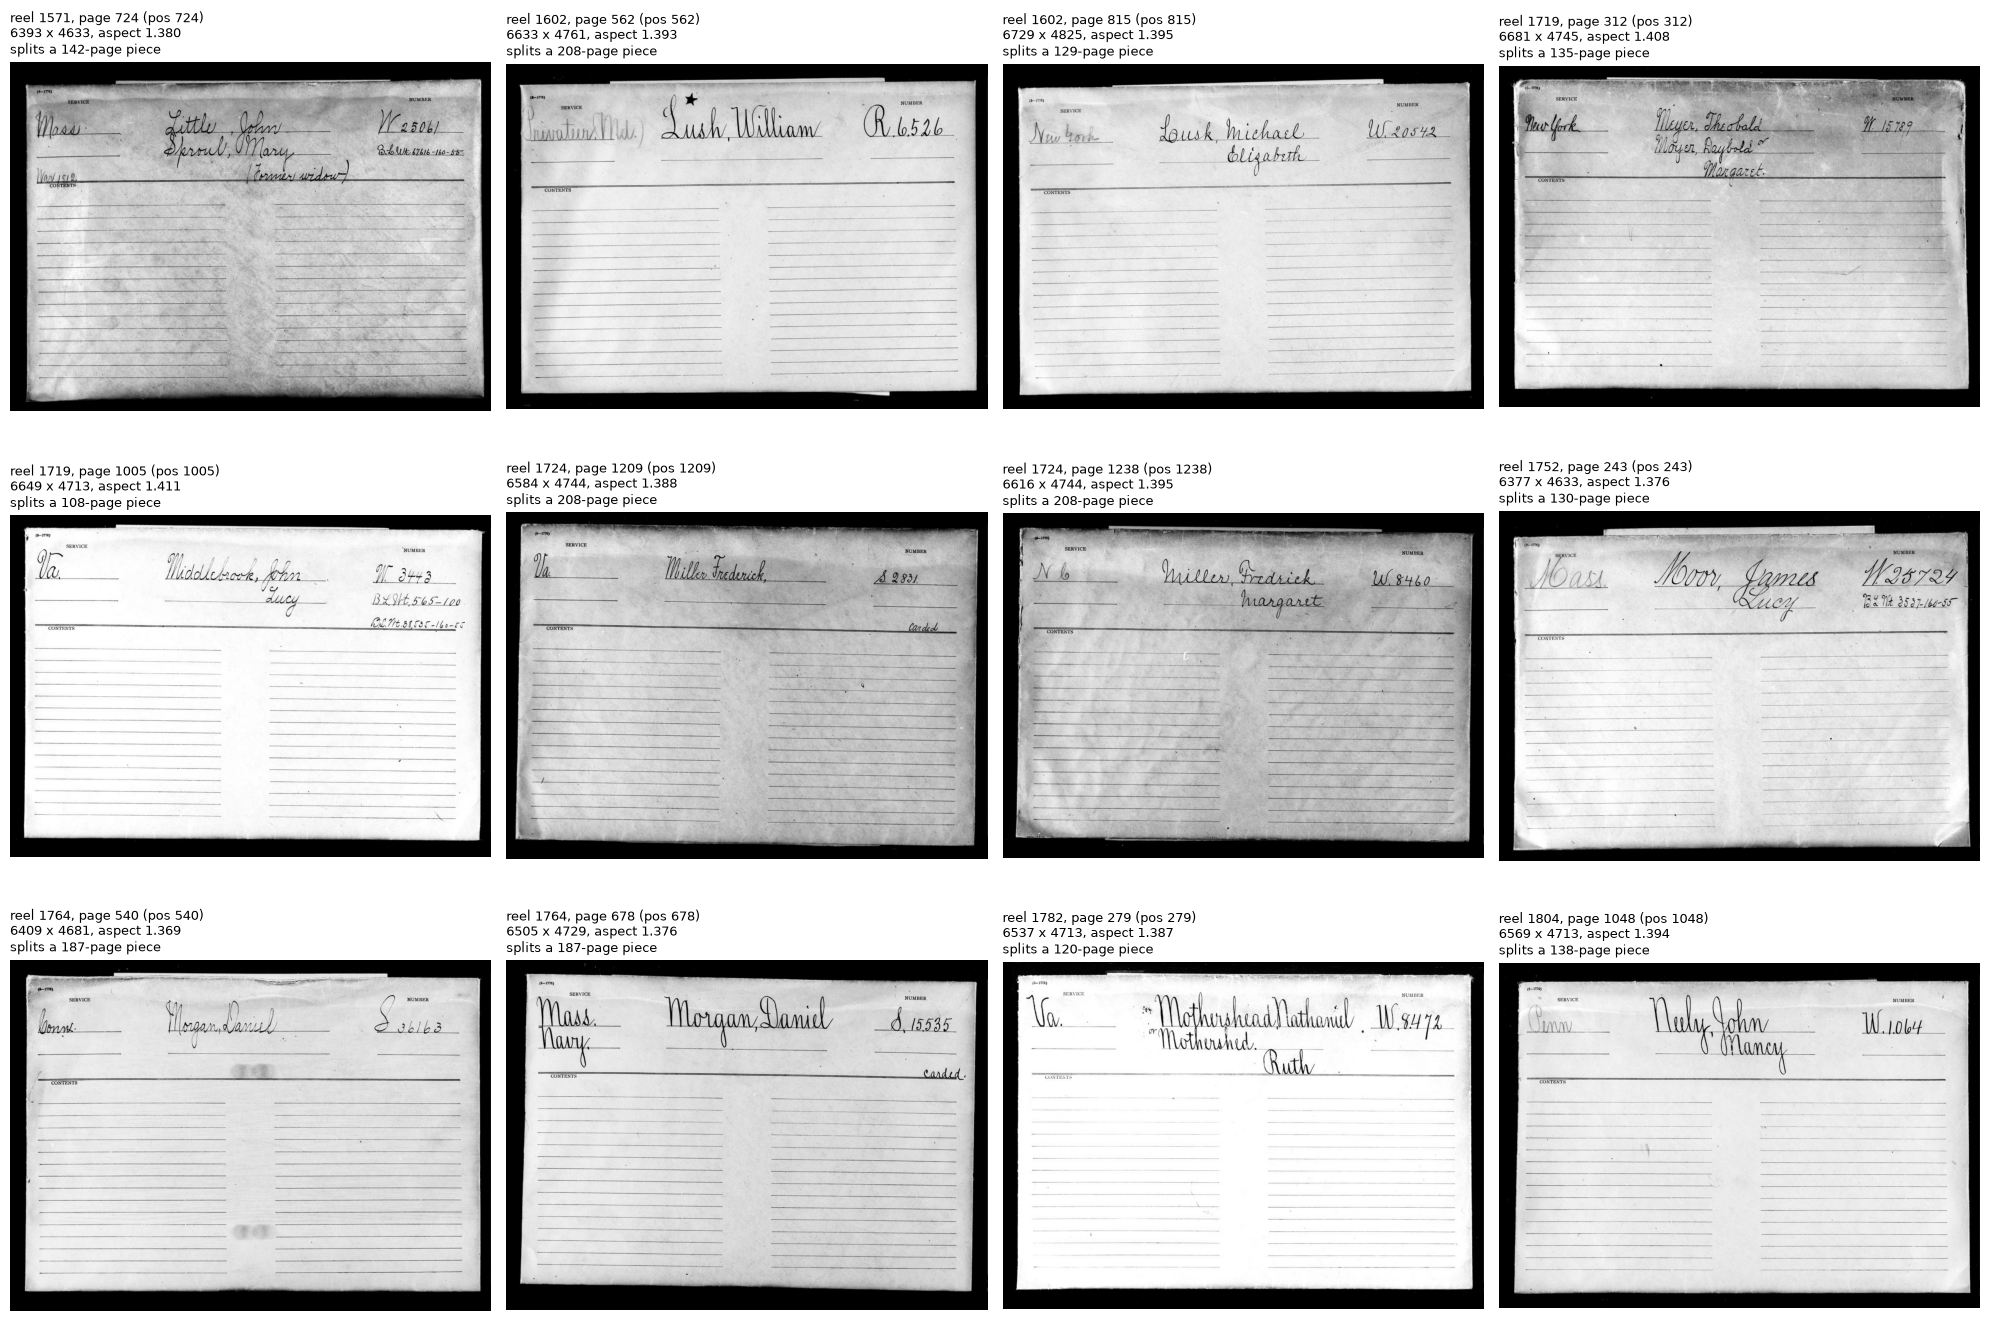

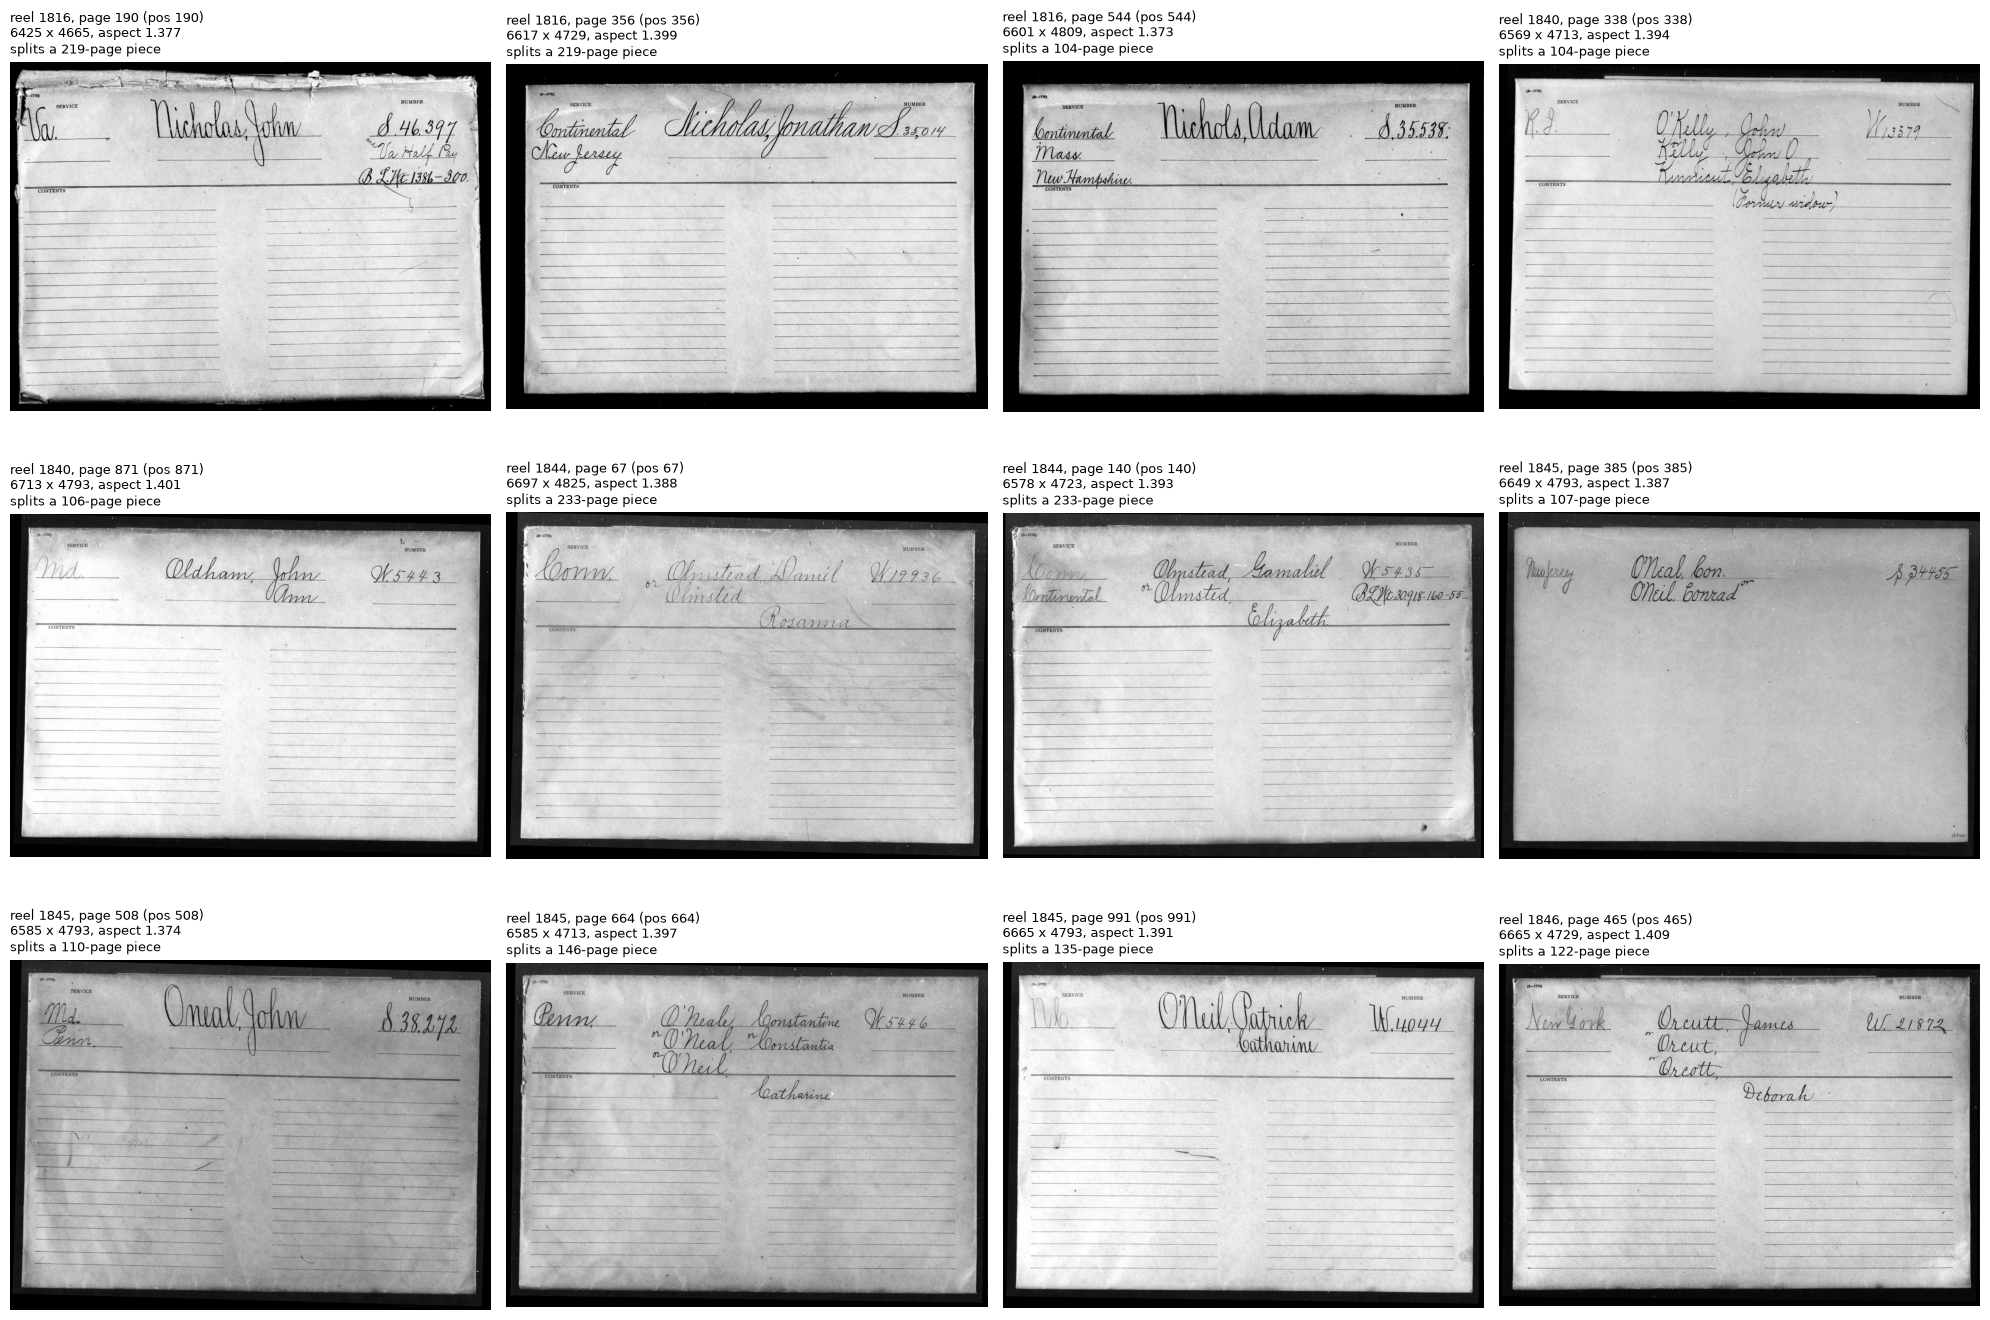

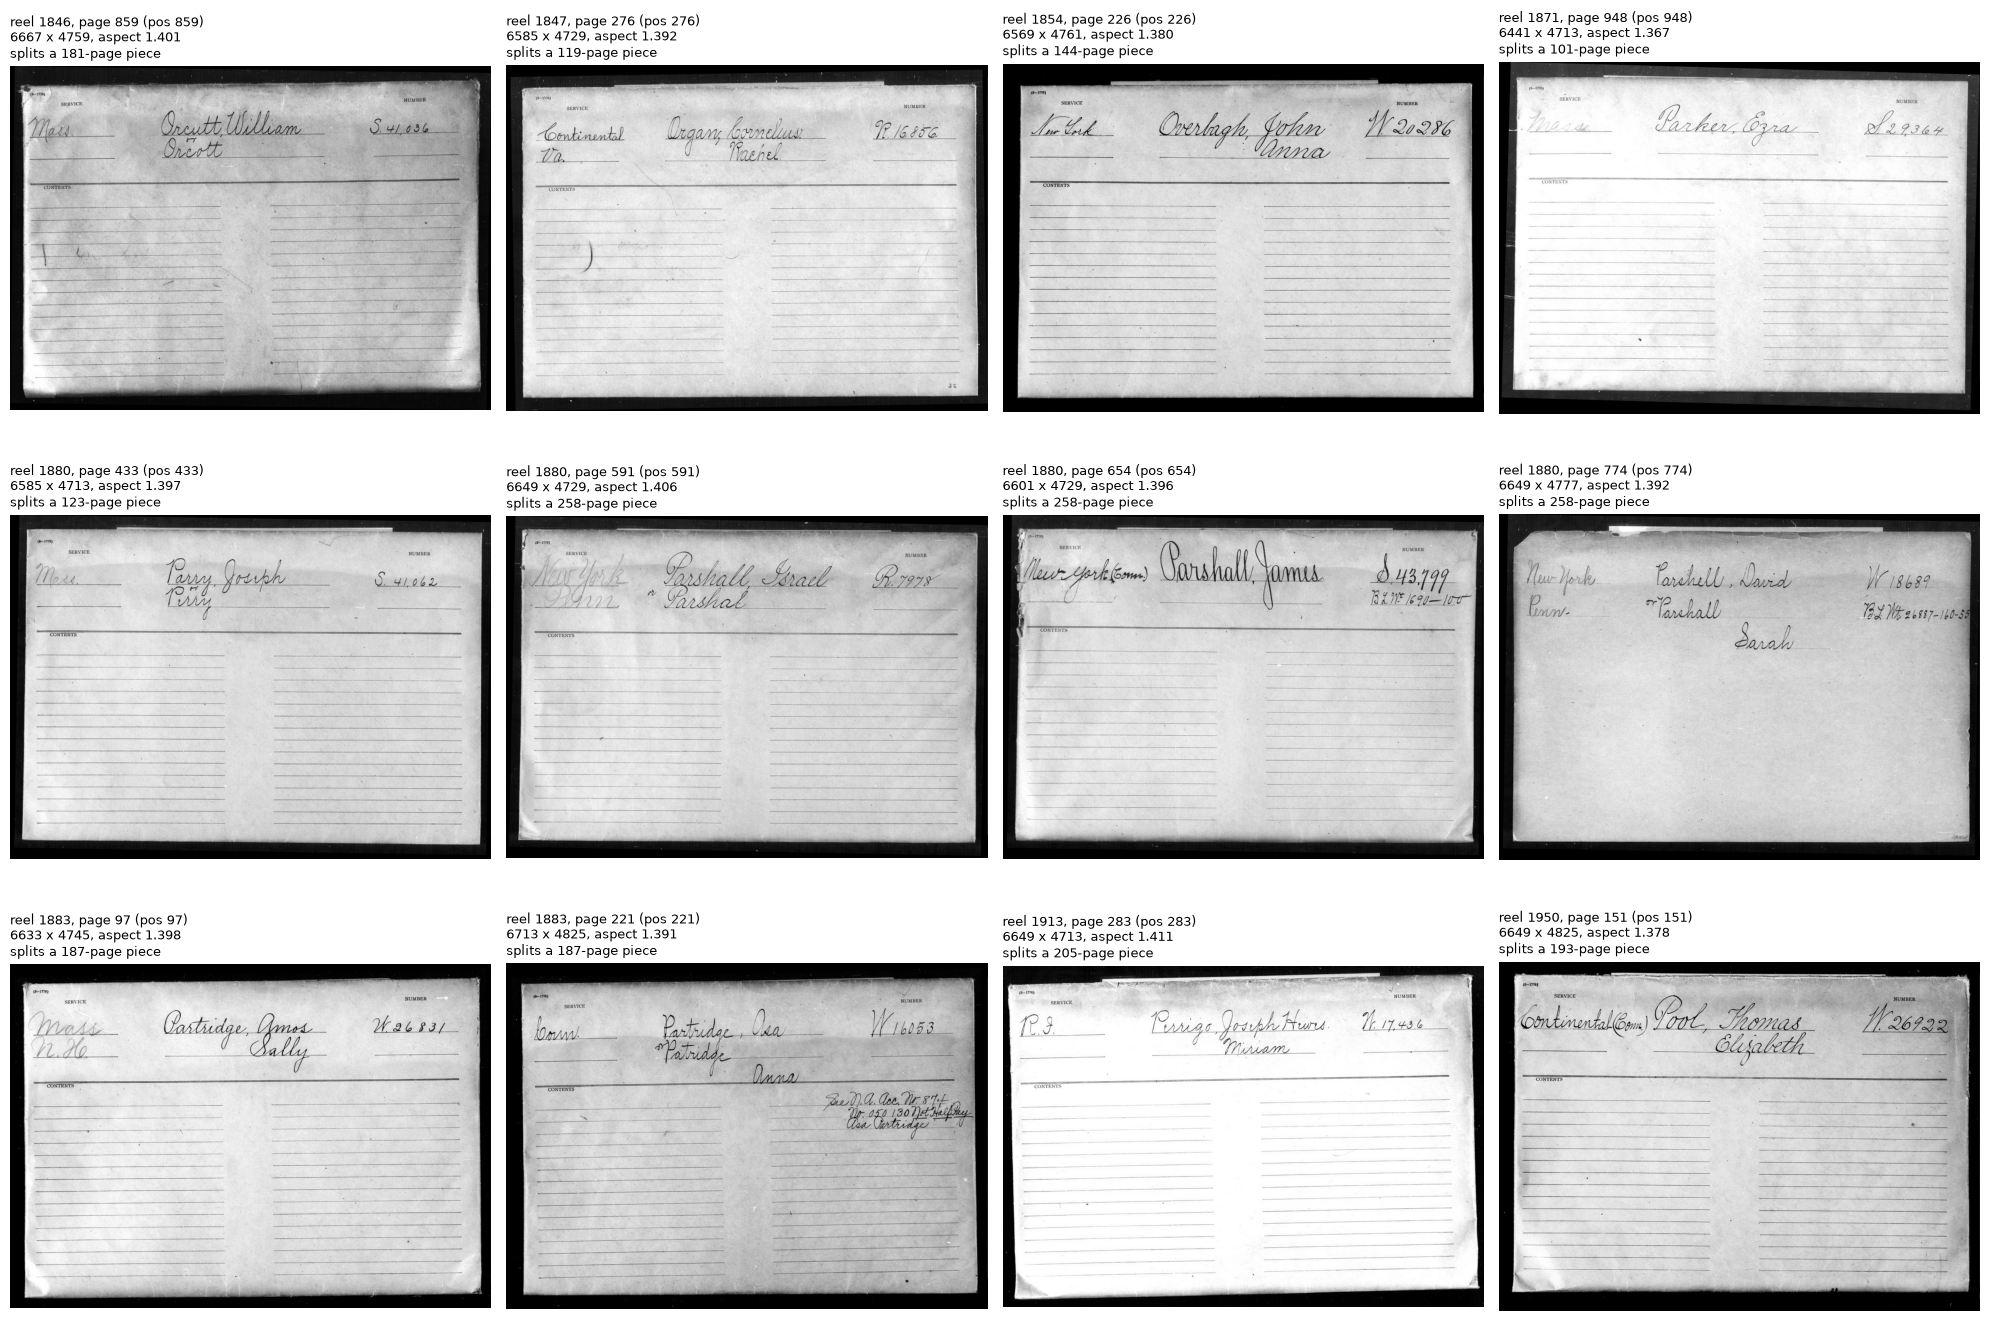

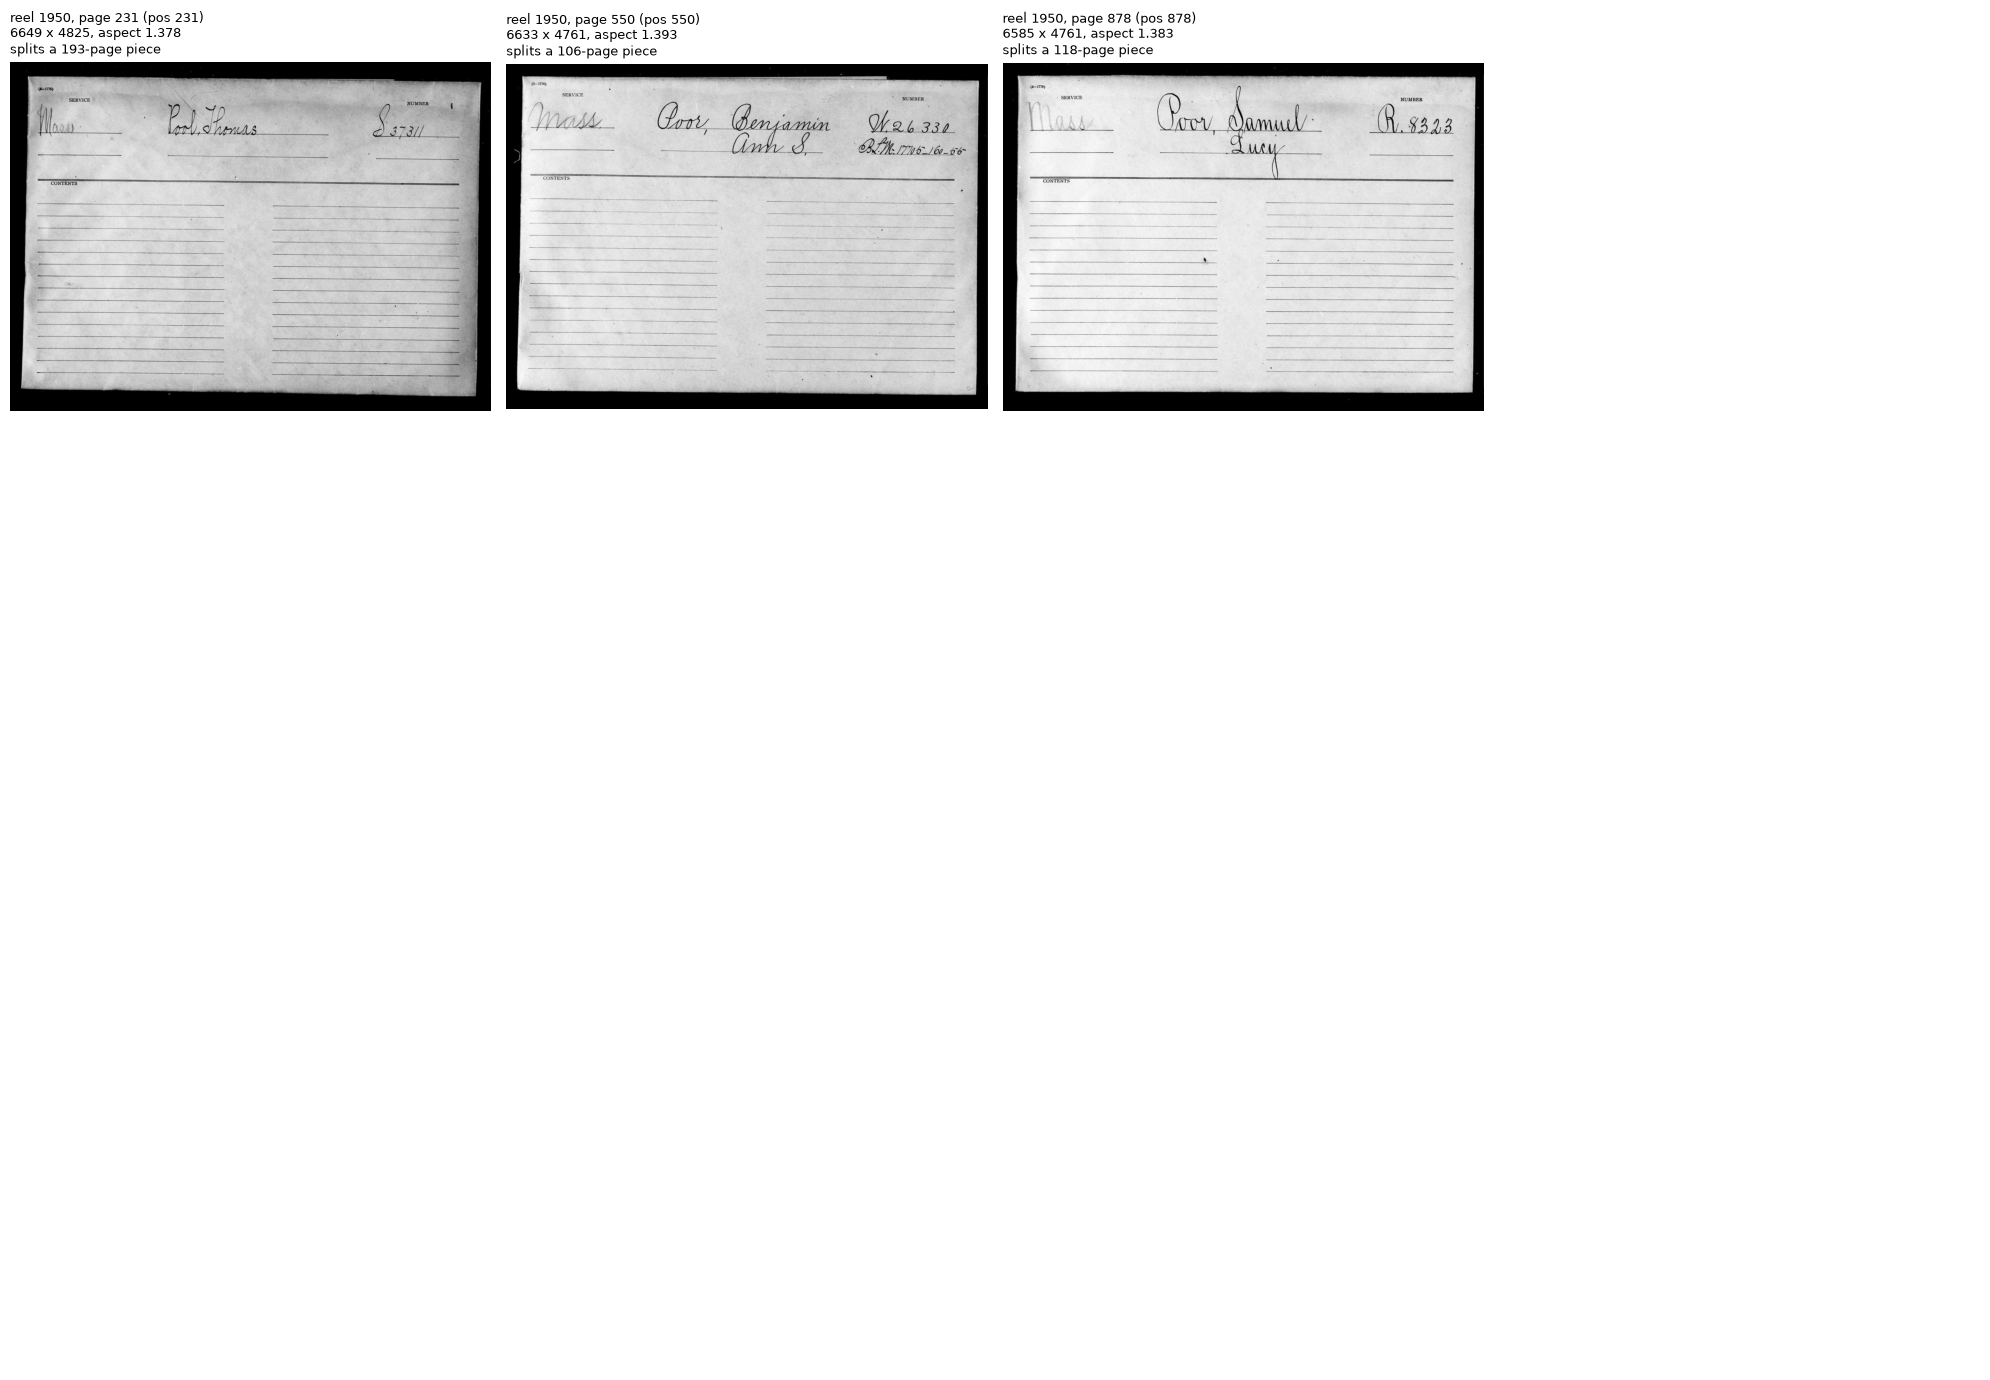

In [17]:
PER_FIG, COLS = 12, 4
ch = chosen.sort_values(["reel", "page"]).reset_index(drop=True)
for start in range(0, len(ch), PER_FIG):
    sub = ch.iloc[start:start + PER_FIG]
    fig, axes = plt.subplots(3, COLS, figsize=(20, 14))
    for ax in axes.ravel():
        ax.axis("off")
    for ax, r in zip(axes.ravel(), sub.itertuples()):
        p = THUMB_DIR / f"{r.reel}_{r.page:04d}.jpg"
        if p.exists():
            ax.imshow(Image.open(p), cmap="gray")
        ax.set_title(f"reel {r.reel}, page {r.page} (pos {r.pos})\n{r.width} x {r.height}, aspect {r.aspect:.3f}\nsplits a {r.orig_piece_pages}-page piece",
                     fontsize=9, loc="left")
    plt.tight_layout(); plt.show()

## Summary

In [18]:
n_over = (pieces.pages > MAX_PAGES).sum()
print(f'''Tier A cuts only (excluding reel positions 1-{SKIP_FIRST}): {len(pieces):,} pieces, {n_over} over {MAX_PAGES} pages, largest {pieces.pages.max()}.
Adding {int(s_near.added_cut.sum())} Tier B+ cuts: {len(s_near):,} PDFs, {(s_near.pages > MAX_PAGES).sum()} still over {MAX_PAGES} pages, largest {s_near.pages.max()}.
Accepted: no further splitting; the largest PDF is {s_near.pages.max()} pages.''')

Tier A cuts only (excluding reel positions 1-2): 2,434 pieces, 61 over 100 pages, largest 258.
Adding 39 Tier B+ cuts: 2,473 PDFs, 39 still over 100 pages, largest 199.
Accepted: no further splitting; the largest PDF is 199 pages.


## Output: the final split table

One row per PDF to generate. `page_start` / `page_end` are the actual page numbers from the image filenames (inclusive; they can have gaps within a reel, so a PDF should include whichever pages of that reel fall in the range). Saved as `splits.csv`.

In [19]:
pg = df.set_index(["reel", "pos"]).page
splits = s_near.sort_values(["reel", "start"]).reset_index(drop=True)
splits["page_start"] = [pg[(r, s)] for r, s in zip(splits.reel, splits.start)]
splits["page_end"] = [pg[(r, s + n - 1)] for r, s, n in zip(splits.reel, splits.start, splits.pages)]
splits["split_id"] = splits.groupby("reel").cumcount() + 1
splits["cut_type"] = np.where(splits.added_cut, "tier_b_plus", np.where(splits.piece.eq(0) & splits.start.eq(1), "reel_start", "tier_a"))
splits = splits.rename(columns={"pages": "n_pages"})[["reel", "split_id", "page_start", "page_end", "n_pages", "cut_type"]]

assert splits.n_pages.sum() == len(df)                      # every page lands in exactly one PDF
splits.to_csv("splits.csv", index=False)
print(f"{len(splits):,} PDFs across {splits.reel.nunique()} reels, {splits.n_pages.sum():,} pages, largest {splits.n_pages.max()}. Wrote splits.csv")
splits.head(20)

2,473 PDFs across 74 reels, 75,804 pages, largest 199. Wrote splits.csv


,reel,split_id,page_start,page_end,n_pages,cut_type
0,1525,1,1,17,17,reel_start
1,1525,2,18,78,61,tier_a
2,1525,3,79,96,18,tier_a
3,1525,4,97,97,1,tier_a
4,1525,5,98,98,1,tier_a
5,1525,6,99,125,27,tier_a
6,1525,7,126,136,11,tier_a
7,1525,8,137,176,40,tier_a
8,1525,9,177,211,35,tier_a
9,1525,10,212,212,1,tier_a
